# ClientCo — Clients, rythme d'achat et définition d'un client « perdu »

**Objectif** : savoir qui sont les clients (Q3), **ce qu'est un client perdu** (Q4, la question la plus structurante du modèle) et combien de CA est en jeu (Q5). Ce notebook donne les ordres de grandeur ; le périmètre et le label retenus sont fixés dans `04_churn_scope_total_vs_partial` et `06_label_horizon_calibration`, et résumés dans `docs/02_modeling_decisions.md`.

> **Définition du jour d'achat dans ce notebook.** Les notebooks 01 à 03 gardent la définition de l'exploration (ligne de vente strictement positive, `rev_pos`) ; à partir du notebook 04, le jour d'achat est le CA net des retours du jour > 0,01 € (décision du 24/11 : 118 009 clients au lieu de 119 656, CA de référence −6 %). Les conclusions de ces trois notebooks ne changent pas ; les décisions de périmètre et de label s'appuient sur les notebooks 04 à 08.

## 0. Setup

Le CSV fait **4,2 Go / 63 M de lignes** : impossible à charger dans pandas sur un laptop. On utilise **DuckDB** : conversion unique en Parquet (~1 min, colonnée et compressée), puis on agrège en SQL et on ne rapatrie dans pandas que de petites tables pour tracer.

In [1]:
from pathlib import Path
import time
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.max_columns", 50, "display.width", 200, "display.float_format", lambda x: f"{x:,.3f}")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CSV = next((p for p in (ROOT / "data" / "dataset_sales_2026.csv", ROOT / "dataset_sales_2026.csv") if p.exists()), ROOT / "dataset_sales_2026.csv")
PARQUET = ROOT / "data" / "sales.parquet"

con = duckdb.connect()
con.execute("SET memory_limit='4GB'")
(ROOT / "data").mkdir(exist_ok=True)
con.execute(f"SET temp_directory='{ROOT / 'data' / '.duckdb_tmp'}'")


def q(sql: str) -> pd.DataFrame:
    """Run a SQL query and return a pandas DataFrame."""
    return con.execute(sql).fetchdf()


if not PARQUET.exists():
    t0 = time.time()
    con.execute(f"""
        COPY (SELECT * FROM read_csv('{CSV}', delim=';', header=true, columns={{
            'date_order':'DATE','date_invoice':'DATE','product_id':'BIGINT','client_id':'BIGINT',
            'sales_net':'DOUBLE','quantity':'DOUBLE','order_channel':'VARCHAR','branch_id':'BIGINT'}}))
        TO '{PARQUET}' (FORMAT parquet, COMPRESSION zstd)""")
    print(f"CSV -> Parquet en {time.time() - t0:.0f}s")

con.execute(f"CREATE OR REPLACE VIEW sales AS SELECT * FROM read_parquet('{PARQUET}')")
q("SELECT * FROM sales LIMIT 5")

,date_order,date_invoice,product_id,client_id,sales_net,quantity,order_channel,branch_id
0,2022-09-25,2022-09-25,2376333,188502,155.443,3.000,online,2732
1,2022-09-25,2022-09-25,2520527,835089,16.394,3.000,at the store,10279
2,2022-09-25,2022-09-25,2536756,1977896,365.766,21.000,online,6184
3,2022-09-25,2022-09-25,3028673,598816,8.599,201.000,at the store,4200
4,2022-09-25,2022-09-25,203377,2086861,"1,093.374",3.000,by phone,7051


### Paramètres de la « photo » (modifiables)

Pour parler de churn il faut une **date d'observation T** : on regarde le passé (< T) pour décrire un client, et le futur (≥ T) pour savoir s'il est parti.
- `BASE_DAYS` : population suivie = clients ayant acheté au moins une fois dans les `BASE_DAYS` derniers jours avant T.
- `HORIZON` : un client est *churné* s'il n'achète plus pendant `HORIZON` jours après T.

Le dataset s'arrête le 22/09/2024 ; la dernière photo possible avec 180 jours d'horizon est donc le 22/03/2024. La section 2 de ce notebook justifie ces choix.

In [2]:
T_SNAP = "2024-03-22"   # date de la photo principale
BASE_DAYS = 180         # population = clients actifs dans les 180 derniers jours
HORIZON = 180           # churn = aucun achat pendant les 180 jours suivants
N_REPS = 200            # nombre de commerciaux (Head of Sales)

### Style graphique
Palette catégorielle validée (ordre fixe : une couleur = une entité), rampe bleue pour les magnitudes, gris neutres pour la structure, orange pour « ce qui alerte ». Fond clair pour que les figures restent lisibles quel que soit le thème de l'éditeur.

In [3]:
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100", magenta="#e87ba4",
         green="#008300", violet="#6250d6", red="#e34948")
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
CMAP = LinearSegmentedColormap.from_list("seq_blue", SEQ)
NEUTRAL = "#b9b8b0"

# Une couleur par canal, identique dans tout le notebook
CHANNEL_COLOR = {"by phone": C["orange"], "at the store": C["blue"], "online": C["aqua"],
                 "during the visit of a sales rep": C["yellow"], "other": C["magenta"]}
CHANNEL_LABEL = {"by phone": "Téléphone", "at the store": "En agence", "online": "En ligne",
                 "during the visit of a sales rep": "Visite commercial", "other": "Autre"}

plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"], "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": INK,
    "lines.linewidth": 2, "figure.dpi": 110, "legend.frameon": False, "legend.fontsize": 9,
    "axes.labelsize": 9.5, "xtick.labelsize": 9, "ytick.labelsize": 9,
})


def headline(fig, title, sub=None):
    """Action title (the takeaway) + optional muted subtitle, left-aligned above the figure."""
    h = fig.get_figheight()
    fig.text(0.005, 1 + (0.30 if sub else 0.12) / h, title, fontsize=13, fontweight="bold", color=INK, ha="left", va="bottom")
    if sub:
        fig.text(0.005, 1 + 0.08 / h, sub, fontsize=9.5, color=INK2, ha="left", va="bottom")


def fmt_m(x, _=None):
    return f"{x / 1e6:,.0f}"


def pct_axis(ax, axis="y", decimals=0):
    f = mtick.PercentFormatter(1.0, decimals=decimals)
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(f)


def label_end(ax, x, y, text, dx=6, **kw):
    """Direct label at the end of a line (secondary ink, never the series colour)."""
    ax.annotate(text, (x, y), xytext=(dx, 0), textcoords="offset points", va="center", color=INK2, fontsize=9, **kw)


def pct(x, d=1):
    return f"{100 * x:.{d}f} %"

### Table (client, jour d'achat)

Construite une fois à partir du Parquet (une passe sur les 63 M de lignes), comme dans `01_data_quality_and_activity_overview`.

In [8]:
# Daily client x day table (one pass over the 63M lines), then purchase days only.
t0 = time.time()
con.execute("""
CREATE OR REPLACE TABLE cd AS
SELECT client_id, date_order AS d,
       sum(sales_net)                                   AS rev_net,
       sum(greatest(sales_net, 0))                      AS rev_pos,
       sum(least(sales_net, 0))                         AS rev_neg,
       count(*)                                         AS n_lines,
       count(DISTINCT product_id)                       AS n_prod,
       arg_max(branch_id, greatest(sales_net, 0))       AS branch_id,
       arg_max(order_channel, greatest(sales_net, 0))   AS channel,
       avg(least(greatest(date_diff('day', date_order, date_invoice), 0), 365)) AS lag_mean
FROM sales GROUP BY client_id, date_order""")
con.execute("CREATE OR REPLACE TABLE bd AS SELECT * FROM cd WHERE rev_pos > 0")
cnt = q("SELECT (SELECT count(*) FROM cd) AS client_days, (SELECT count(*) FROM bd) AS purchase_days").iloc[0]
print(f"{cnt['client_days']:,.0f} (client, jour) · dont {cnt['purchase_days']:,.0f} jours d'achat · construit en {time.time() - t0:.0f}s")

7,955,289 (client, jour) · dont 7,953,336 jours d'achat · construit en 16s


In [ ]:
order = ["at the store", "by phone", "online", "during the visit of a sales rep", "other"]   # ordre d'affichage des canaux

## 1. Qui sont les clients ?

**Question Q3** — le Head of Sales décrit une base « large et diverse » : acheteurs occasionnels, PME régulières, grands comptes. Si c'est vrai dans les données, **un seul modèle et une seule définition de churn ne tiendront pas** : il faudra raisonner par rythme d'achat.

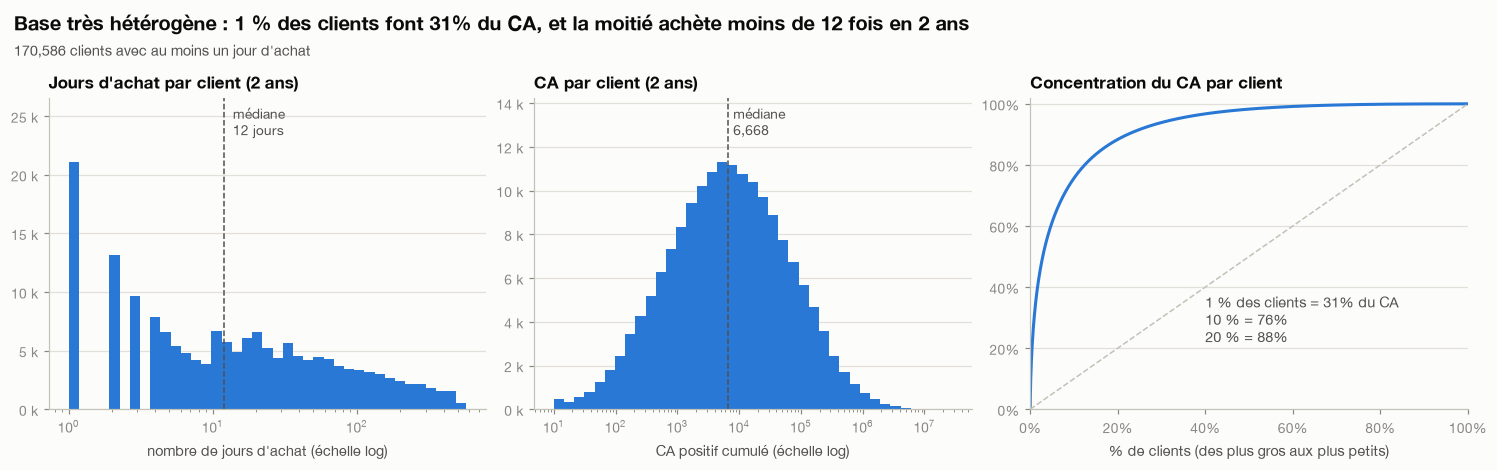

In [13]:
cl = q("""
SELECT client_id, min(d) AS first_d, max(d) AS last_d, count(*) AS n_days,
       sum(rev_pos) AS rev_pos, sum(rev_net) AS rev_net, -sum(rev_neg) / sum(rev_pos) AS ret_share,
       count(DISTINCT branch_id) AS n_branch, count(DISTINCT channel) AS n_channel, mode(channel) AS channel
FROM bd GROUP BY 1""")
FREQ2Y_BINS = [0, 1, 3, 11, 35, 103, np.inf]
FREQ2Y_LABELS = ["1 achat", "2–3", "4–11", "12–35", "36–103", "104+"]
cl["freq_class"] = pd.cut(cl["n_days"], FREQ2Y_BINS, labels=FREQ2Y_LABELS)

s = cl.sort_values("rev_pos", ascending=False).reset_index(drop=True)
s["cum"] = s["rev_pos"].cumsum() / s["rev_pos"].sum()
s["rank"] = (np.arange(len(s)) + 1) / len(s)
top = {p: s.loc[s["rank"] <= p, "cum"].iloc[-1] for p in (0.01, 0.05, 0.10, 0.20)}

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6), constrained_layout=True)
b = np.logspace(0, np.log10(cl["n_days"].max()), 40)
axes[0].hist(cl["n_days"], bins=b, color=C["blue"])
axes[0].set_xscale("log")
axes[0].set_ylim(top=axes[0].get_ylim()[1] * 1.2)
axes[0].axvline(cl["n_days"].median(), color=INK2, ls="--", lw=1)
axes[0].text(cl["n_days"].median() * 1.15, axes[0].get_ylim()[1] * 0.88, f"médiane\n{cl['n_days'].median():.0f} jours", fontsize=9, color=INK2)
axes[0].set_title("Jours d'achat par client (2 ans)")
axes[0].set_xlabel("nombre de jours d'achat (échelle log)")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1e3:,.0f} k"))
b = np.logspace(1, np.log10(cl["rev_pos"].max()), 40)
axes[1].hist(cl["rev_pos"].clip(lower=10), bins=b, color=C["blue"])
axes[1].set_xscale("log")
axes[1].set_ylim(top=axes[1].get_ylim()[1] * 1.2)
axes[1].axvline(cl["rev_pos"].median(), color=INK2, ls="--", lw=1)
axes[1].text(cl["rev_pos"].median() * 1.2, axes[1].get_ylim()[1] * 0.88, f"médiane\n{cl['rev_pos'].median():,.0f}", fontsize=9, color=INK2)
axes[1].set_title("CA par client (2 ans)")
axes[1].set_xlabel("CA positif cumulé (échelle log)")
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1e3:,.0f} k"))
axes[2].plot(s["rank"], s["cum"], color=C["blue"])
axes[2].plot([0, 1], [0, 1], color=AXIS, lw=1, ls="--")
axes[2].text(0.4, 0.22, f"1 % des clients = {top[0.01]:.0%} du CA\n10 % = {top[0.10]:.0%}\n20 % = {top[0.20]:.0%}", fontsize=9.5, color=INK2)
axes[2].set_title("Concentration du CA par client")
axes[2].set_xlabel("% de clients (des plus gros aux plus petits)")
for ax_ in (axes[2],):
    pct_axis(ax_)
    pct_axis(ax_, "x")
    ax_.set_xlim(0, 1)
    ax_.set_ylim(0, 1.02)
for ax_ in axes[:2]:
    ax_.grid(axis="x", visible=False)
headline(fig, f"Base très hétérogène : 1 % des clients font {top[0.01]:.0%} du CA, et la moitié achète moins de {cl['n_days'].median():.0f} fois en 2 ans",
         f"{len(cl):,.0f} clients avec au moins un jour d'achat")
plt.show()

La distribution confirme l'interview : une très longue traîne de petits clients occasionnels et une **minorité de gros comptes qui concentre l'essentiel du CA**. Pour le churn, cela change tout : *perdre 1 000 petits clients n'a pas le même coût que perdre 10 grands comptes*, et une métrique en « nombre de clients » mentira. **Il faudra pondérer par le CA** (ou segmenter).

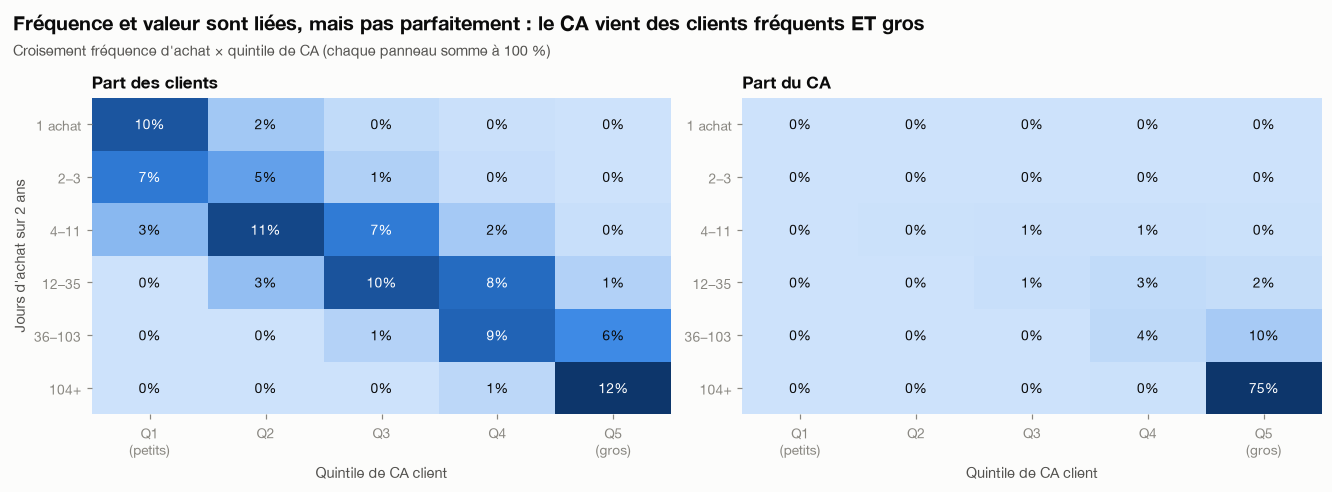

,clients,part_clients,part_ca,ca_moyen_par_client
freq_class,,,,
1 achat,21087,0.124,0.003,"1,277.260"
2–3,22837,0.134,0.006,"2,411.691"
4–11,39394,0.231,0.022,"5,628.784"
12–35,37530,0.220,0.068,"17,939.981"
36–103,27167,0.159,0.145,"52,982.611"
104+,22571,0.132,0.757,"333,544.759"


In [14]:
cl["rev_q"] = pd.qcut(cl["rev_pos"].rank(method="first"), 5, labels=["Q1\n(petits)", "Q2", "Q3", "Q4", "Q5\n(gros)"])
cnt = cl.pivot_table(index="freq_class", columns="rev_q", values="client_id", aggfunc="count", observed=False)
rev = cl.pivot_table(index="freq_class", columns="rev_q", values="rev_pos", aggfunc="sum", observed=False)
cnt, rev = cnt / cnt.to_numpy().sum(), rev / rev.to_numpy().sum()


def heat(ax, M, title, fmt="{:.0%}", vmax=None, cmap=CMAP):
    vmax = vmax if vmax is not None else np.nanmax(M.to_numpy())
    ax.imshow(M.to_numpy(), cmap=cmap, vmin=0, vmax=vmax, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.iat[i, j]
            if pd.notna(v):
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=9, color="white" if v > vmax * 0.55 else INK)
    ax.set_xticks(range(M.shape[1]), [str(c) for c in M.columns])
    ax.set_yticks(range(M.shape[0]), [str(i) for i in M.index])
    ax.grid(False)
    ax.set_title(title)
    for sp in ax.spines.values():
        sp.set_visible(False)


fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
heat(axes[0], cnt, "Part des clients")
heat(axes[1], rev, "Part du CA")
axes[0].set_ylabel("Jours d'achat sur 2 ans")
for ax_ in axes:
    ax_.set_xlabel("Quintile de CA client")
headline(fig, "Fréquence et valeur sont liées, mais pas parfaitement : le CA vient des clients fréquents ET gros",
         "Croisement fréquence d'achat × quintile de CA (chaque panneau somme à 100 %)")
plt.show()
seg_tbl = cl.groupby("freq_class", observed=False).agg(clients=("client_id", "count"), ca=("rev_pos", "sum"))
seg_tbl["part_clients"] = seg_tbl["clients"] / seg_tbl["clients"].sum()
seg_tbl["part_ca"] = seg_tbl["ca"] / seg_tbl["ca"].sum()
seg_tbl["ca_moyen_par_client"] = seg_tbl["ca"] / seg_tbl["clients"]
seg_tbl.drop(columns="ca")

Les clients à **104+ jours d'achat sur 2 ans** (en moyenne au moins un achat par semaine) ne sont que **13 % des clients mais ~76 % du CA**. À l'autre bout, les acheteurs à 1-3 jours d'achat (**26 % des clients**) pèsent **moins de 1 % du CA** : leur « départ » est à la fois peu coûteux et quasi indiscernable d'un achat ponctuel (les « occasional shoppers » de l'interview).

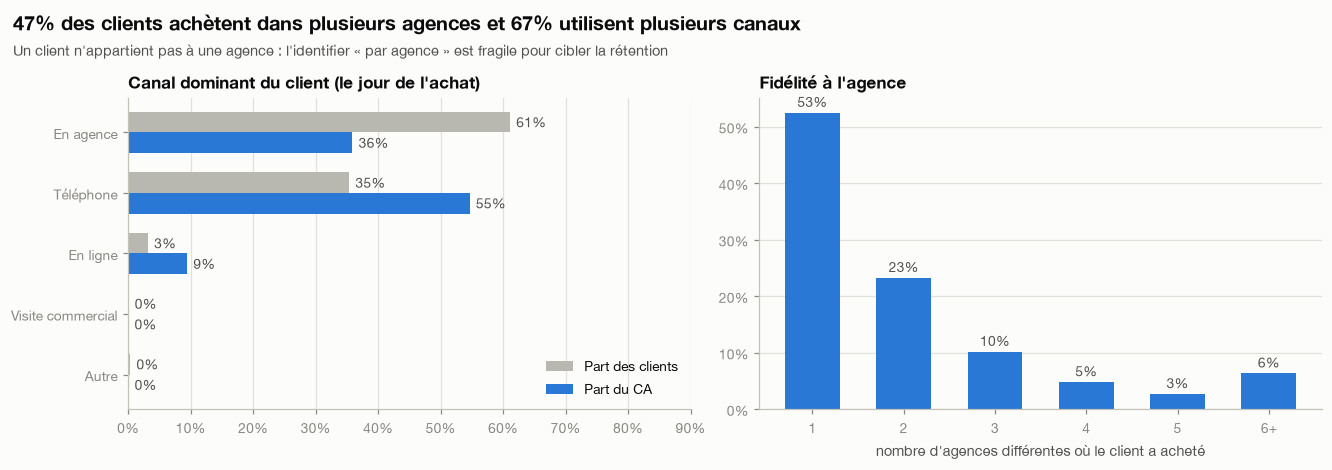

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), constrained_layout=True)
dom = cl.groupby("channel").agg(clients=("client_id", "count"), ca=("rev_pos", "sum")).loc[order]
y = np.arange(len(order))[::-1]
h = 0.34
axes[0].barh(y + h / 2, dom["clients"] / dom["clients"].sum(), height=h, color=NEUTRAL, label="Part des clients")
axes[0].barh(y - h / 2, dom["ca"] / dom["ca"].sum(), height=h, color=C["blue"], label="Part du CA")
for yi, a, b_ in zip(y, dom["clients"] / dom["clients"].sum(), dom["ca"] / dom["ca"].sum()):
    axes[0].text(a + 0.01, yi + h / 2, f"{a:.0%}", va="center", fontsize=9, color=INK2)
    axes[0].text(b_ + 0.01, yi - h / 2, f"{b_:.0%}", va="center", fontsize=9, color=INK2)
axes[0].set_yticks(y, [CHANNEL_LABEL[c] for c in order])
pct_axis(axes[0], "x")
axes[0].set_xlim(0, 0.9)
axes[0].grid(axis="x")
axes[0].grid(axis="y", visible=False)
axes[0].legend(loc="lower right")
axes[0].set_title("Canal dominant du client (le jour de l'achat)")
nb_br = cl["n_branch"].clip(upper=6).value_counts(normalize=True).sort_index()
axes[1].bar(nb_br.index, nb_br.values, width=0.6, color=C["blue"])
for x, v in nb_br.items():
    axes[1].text(x, v + 0.01, f"{v:.0%}", ha="center", fontsize=9, color=INK2)
axes[1].set_xticks(nb_br.index, [str(i) if i < 6 else "6+" for i in nb_br.index])
axes[1].set_xlabel("nombre d'agences différentes où le client a acheté")
pct_axis(axes[1])
axes[1].set_title("Fidélité à l'agence")
multi_ch = (cl["n_channel"] > 1).mean()
multi_br = (cl["n_branch"] > 1).mean()
headline(fig, f"{multi_br:.0%} des clients achètent dans plusieurs agences et {multi_ch:.0%} utilisent plusieurs canaux",
         "Un client n'appartient pas à une agence : l'identifier « par agence » est fragile pour cibler la rétention")
plt.show()

## 2. Rythme d'achat → comment définir un client « perdu » ?

**Question Q4 — la plus structurante du modèle.** Il n'y a pas de colonne « churn » : le contexte B2B est **non contractuel** (le client ne résilie pas, il cesse simplement d'acheter). On doit *inventer* la définition à partir du rythme d'achat observé. Trois pièges : (1) un seuil trop court étiquette « perdus » des clients qui reviendraient, (2) un seuil trop long donne des alertes trop tardives pour agir, (3) un seuil unique ignore que chaque client a son propre rythme.

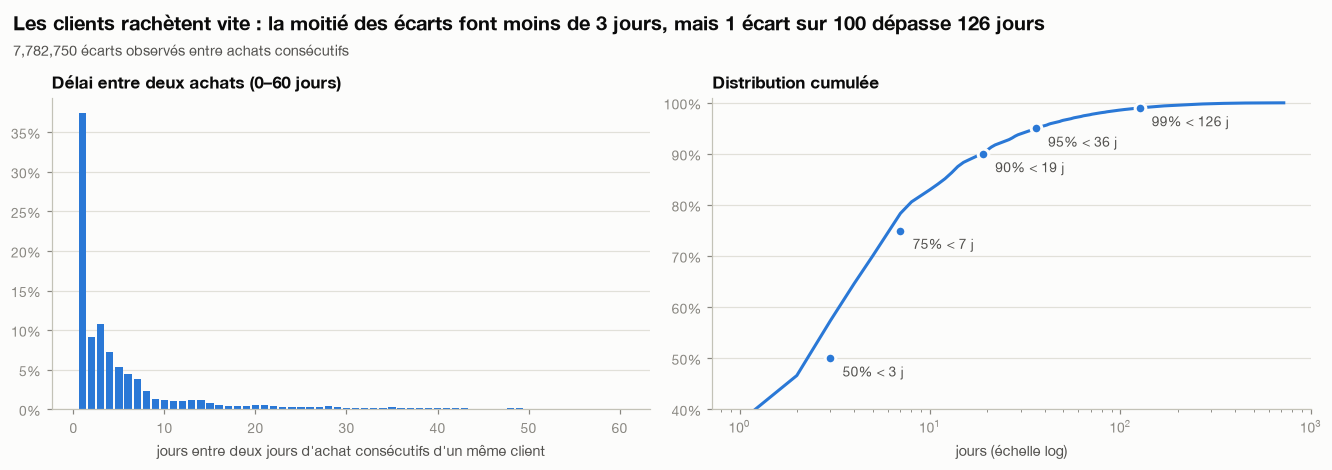

In [16]:
gaps = q("""
WITH g AS (SELECT d - lag(d) OVER (PARTITION BY client_id ORDER BY d) AS gap FROM bd)
SELECT gap, count(*) AS n FROM g WHERE gap IS NOT NULL GROUP BY 1 ORDER BY 1""")
gaps["cdf"] = gaps["n"].cumsum() / gaps["n"].sum()
gq = {p: int(gaps.loc[gaps["cdf"] >= p, "gap"].iloc[0]) for p in (0.5, 0.75, 0.9, 0.95, 0.99)}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), constrained_layout=True)
g60 = gaps[gaps["gap"] <= 60]
axes[0].bar(g60["gap"], g60["n"] / gaps["n"].sum(), width=0.8, color=C["blue"])
pct_axis(axes[0])
axes[0].set_xlabel("jours entre deux jours d'achat consécutifs d'un même client")
axes[0].set_title("Délai entre deux achats (0–60 jours)")
axes[0].grid(axis="x", visible=False)
axes[1].plot(gaps["gap"], gaps["cdf"], color=C["blue"])
axes[1].set_xscale("log")
for p, d in gq.items():
    axes[1].plot([d], [p], "o", color=C["blue"], ms=7, mec=SURF, mew=2)
    axes[1].annotate(f"{p:.0%} < {d} j", (d, p), xytext=(8, -12), textcoords="offset points", fontsize=9, color=INK2)
pct_axis(axes[1])
axes[1].set_ylim(0.4, 1.01)
axes[1].set_xlabel("jours (échelle log)")
axes[1].set_title("Distribution cumulée")
headline(fig, f"Les clients rachètent vite : la moitié des écarts font moins de {gq[0.5]} jours, mais 1 écart sur 100 dépasse {gq[0.99]} jours",
         f"{gaps['n'].sum():,.0f} écarts observés entre achats consécutifs")
plt.show()

La grande majorité des écarts est courte (**médiane 3 jours, 90 % sous 19 jours, 95 % sous ~5 semaines**), mais la **queue est lourde** : 1 % des écarts dépasse 4 mois. Un seuil de churn inférieur à ~4 mois étiquettera à tort comme « perdus » une partie de clients qui reviennent. Mais ces écarts mélangent des clients qui achètent chaque semaine et des clients qui achètent 4 fois par an. Séparons-les :

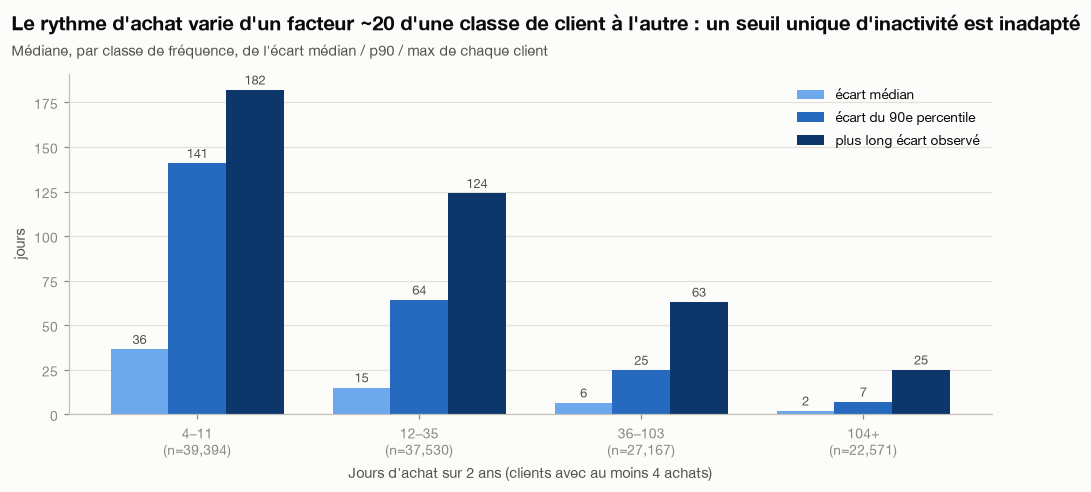

In [17]:
pc = q("""
WITH g AS (SELECT client_id, d, d - lag(d) OVER (PARTITION BY client_id ORDER BY d) AS gap FROM bd)
SELECT client_id, median(gap) AS med_gap, quantile_cont(gap, 0.9) AS p90_gap, max(gap) AS max_gap
FROM g WHERE gap IS NOT NULL GROUP BY 1""").merge(cl[["client_id", "n_days", "freq_class"]], on="client_id")
pc = pc[pc["n_days"] >= 4]
tab = pc.groupby("freq_class", observed=True).agg(clients=("client_id", "count"), med_gap=("med_gap", "median"), p90_gap=("p90_gap", "median"), max_gap=("max_gap", "median"))

fig, ax = plt.subplots(figsize=(9, 3.8), constrained_layout=True)
x = np.arange(len(tab))
w = 0.26
ax.bar(x - w, tab["med_gap"], width=w, color=SEQ[2], label="écart médian")
ax.bar(x, tab["p90_gap"], width=w, color=SEQ[4], label="écart du 90e percentile")
ax.bar(x + w, tab["max_gap"], width=w, color=SEQ[6], label="plus long écart observé")
for xi, (a, b_, c_) in enumerate(zip(tab["med_gap"], tab["p90_gap"], tab["max_gap"])):
    for off, v in zip((-w, 0, w), (a, b_, c_)):
        ax.text(xi + off, v + 3, f"{v:.0f}", ha="center", fontsize=8.5, color=INK2)
ax.set_xticks(x, [f"{i}\n(n={n_:,.0f})" for i, n_ in zip(tab.index, tab["clients"])])
ax.set_xlabel("Jours d'achat sur 2 ans (clients avec au moins 4 achats)")
ax.set_ylabel("jours")
ax.legend(loc="upper right")
headline(fig, "Le rythme d'achat varie d'un facteur ~20 d'une classe de client à l'autre : un seuil unique d'inactivité est inadapté",
         "Médiane, par classe de fréquence, de l'écart médian / p90 / max de chaque client")
plt.show()

Un silence de 60 jours est **un signal d'alarme fort** pour un client qui achète toutes les semaines (écart p90 : 7 jours), et un **non-événement** pour un client à 4-11 achats sur 2 ans (écart médian : 36 jours). Cela plaide pour des features **relatives au rythme du client** (récence ÷ écart habituel) plutôt qu'une récence brute, et pour une évaluation du modèle **par segment de fréquence**.

### Courbe de retour : quand un silence devient-il définitif ?
On prend 7 photos (du 22/09/2023 au 22/03/2024), et pour chaque client actif dans l'année précédente on regarde, **selon son temps de silence**, la probabilité qu'il n'achète plus du tout dans les 180 jours suivants.

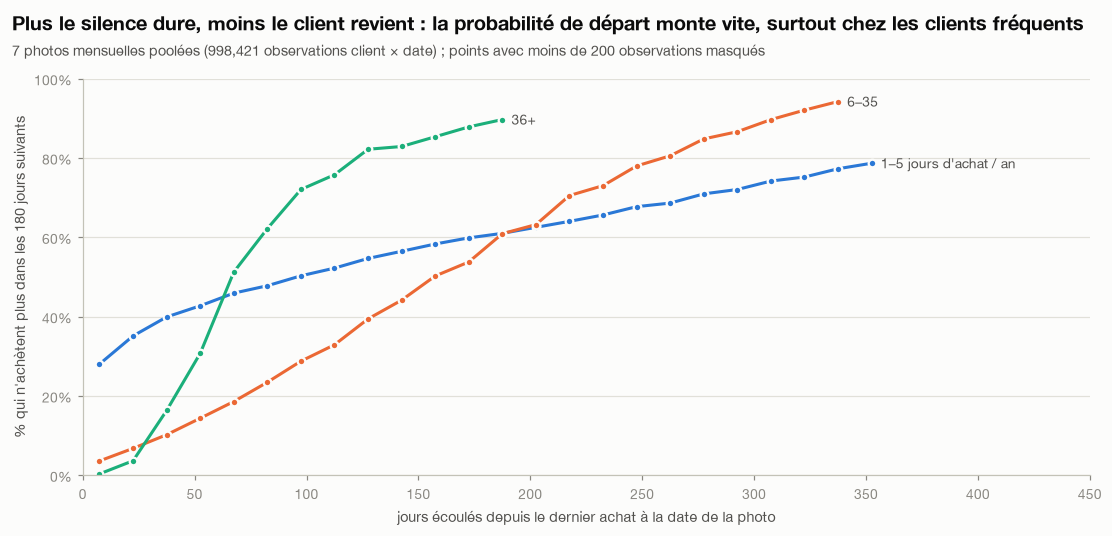

In [18]:
def light_snap(T: str) -> pd.DataFrame:
    """One row per client active in the 365 days before T, with recency and days until next purchase (NaN if none)."""
    return q(f"""
    WITH a AS (
        SELECT client_id, max(d) AS last_d,
               count(*) FILTER (WHERE d >= DATE '{T}' - 365) AS f365,
               sum(rev_pos) FILTER (WHERE d >= DATE '{T}' - 365) AS rev365,
               sum(rev_pos) FILTER (WHERE d >= DATE '{T}' - 180) AS rev180
        FROM bd WHERE d < DATE '{T}' GROUP BY 1),
    f AS (SELECT client_id, min(d) AS next_d FROM bd WHERE d >= DATE '{T}' GROUP BY 1)
    SELECT a.client_id, date_diff('day', a.last_d, DATE '{T}') AS recency, a.f365, a.rev365, a.rev180,
           date_diff('day', DATE '{T}', f.next_d) AS days_to_next
    FROM a LEFT JOIN f USING (client_id) WHERE a.f365 > 0""")


def is_churn(df, horizon):
    """No purchase in [T, T+horizon)."""
    return df["days_to_next"].isna() | (df["days_to_next"] >= horizon)


SNAPS_POOL = ["2023-09-22", "2023-10-22", "2023-11-22", "2023-12-22", "2024-01-22", "2024-02-22", "2024-03-22"]
pool = pd.concat([light_snap(t).assign(T=t) for t in SNAPS_POOL], ignore_index=True)
pool["churn"] = is_churn(pool, 180)
FREQ_BINS = [0, 5, 35, np.inf]
FREQ_LABELS = ["1–5 jours d'achat / an", "6–35", "36+"]
pool["freq_class"] = pd.cut(pool["f365"], FREQ_BINS, labels=FREQ_LABELS)
pool["rec_bin"] = (pool["recency"] // 15 * 15).clip(upper=345)
curve = pool.groupby(["freq_class", "rec_bin"], observed=True)["churn"].agg(["mean", "count"]).reset_index()

fig, ax = plt.subplots(figsize=(10, 4.2), constrained_layout=True)
for lab, colr in zip(FREQ_LABELS, [C["blue"], C["orange"], C["aqua"]]):
    d = curve[(curve["freq_class"] == lab) & (curve["count"] >= 200)]
    ax.plot(d["rec_bin"] + 7.5, d["mean"], color=colr, marker="o", ms=5, mec=SURF, mew=1.5)
    label_end(ax, d["rec_bin"].iloc[-1] + 7.5, d["mean"].iloc[-1], lab)
pct_axis(ax)
ax.set_ylim(0, 1)
ax.set_xlim(0, 450)
ax.set_xlabel("jours écoulés depuis le dernier achat à la date de la photo")
ax.set_ylabel("% qui n'achètent plus dans les 180 jours suivants")
headline(fig, "Plus le silence dure, moins le client revient : la probabilité de départ monte vite, surtout chez les clients fréquents",
         f"7 photos mensuelles poolées ({len(pool):,.0f} observations client × date) ; points avec moins de 200 observations masqués")
plt.show()

**Lecture** :
- Un client **fréquent (36+ jours d'achat/an)** passe de ~0 % à **~50 % de probabilité de départ en à peine 60-70 jours de silence**, et à ~70 % à 100 jours : c'est la zone d'**alerte précoce** exploitable (et c'est là que se trouve la valeur).
- Le client occasionnel (1-5 jours/an) a déjà ~30 % de risque dès son dernier achat (beaucoup d'achats uniques), et le risque ne grimpe ensuite que lentement : le silence est peu informatif pour lui.
- Les courbes sont **continues** : il n'existe pas de seuil naturel net, la définition de churn est un **choix business** (arbitrage entre précocité de l'alerte et fiabilité du label).

### Sensibilité de la définition (base suivie × horizon)
Taux de churn (clients, à gauche) et part du CA des churners (à droite) selon la fenêtre de la population suivie et l'horizon sans achat, photo du 22/12/2023.

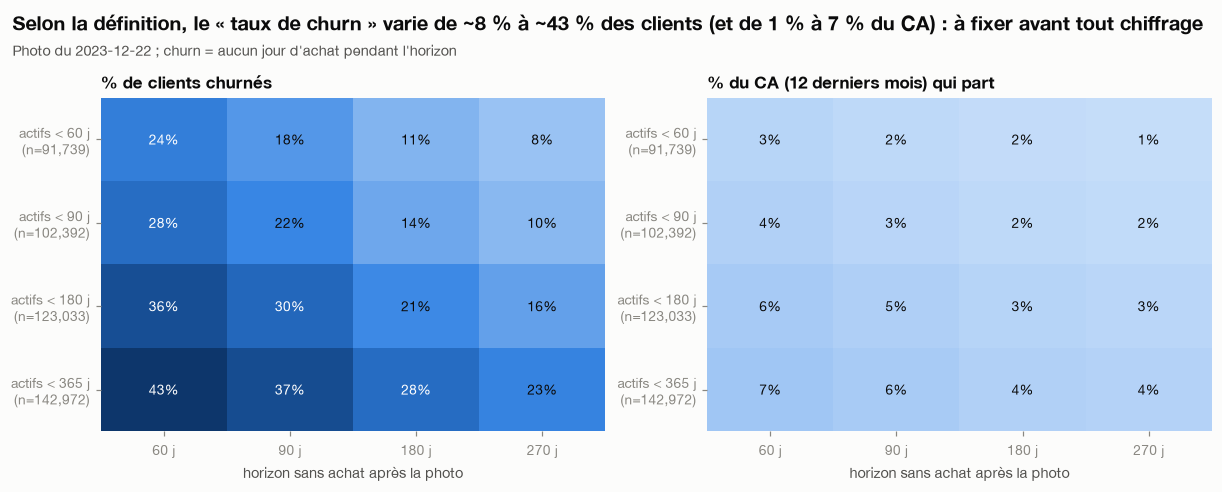

In [19]:
T_GRID = "2023-12-22"
g = light_snap(T_GRID)
BASES = [60, 90, 180, 365]
HORIZONS = [60, 90, 180, 270]
r_cnt = pd.DataFrame({h_: [is_churn(g[g["recency"] <= b_], h_).mean() for b_ in BASES] for h_ in HORIZONS}, index=BASES)
r_rev = pd.DataFrame({h_: [(g[g["recency"] <= b_]["rev365"] * is_churn(g[g["recency"] <= b_], h_)).sum() / g[g["recency"] <= b_]["rev365"].sum() for b_ in BASES] for h_ in HORIZONS}, index=BASES)
r_n = pd.Series({b_: int((g["recency"] <= b_).sum()) for b_ in BASES})
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
vmax = r_cnt.to_numpy().max()
heat(axes[0], r_cnt, "% de clients churnés", vmax=vmax)
heat(axes[1], r_rev, "% du CA (12 derniers mois) qui part", vmax=vmax)
for ax_ in axes:
    ax_.set_yticks(range(len(BASES)), [f"actifs < {b_} j\n(n={r_n[b_]:,.0f})" for b_ in BASES])
    ax_.set_xticks(range(len(HORIZONS)), [f"{h_} j" for h_ in HORIZONS])
    ax_.set_xlabel("horizon sans achat après la photo")
headline(fig, "Selon la définition, le « taux de churn » varie de ~8 % à ~43 % des clients (et de 1 % à 7 % du CA) : à fixer avant tout chiffrage",
         f"Photo du {T_GRID} ; churn = aucun jour d'achat pendant l'horizon")
plt.show()

**Ce que dit ce tableau** : quelle que soit la définition, le **CA concerné est 5 à 8 fois plus faible que la part de clients** : les clients qui partent sont des **petits clients**. Et plus on suit large (base 365 jours) ou court (horizon 60 j), plus on inclut des clients déjà quasi partis ou simplement en pause, ce qui gonfle artificiellement le churn.

**Définition retenue pour la suite** (modifiable en haut du notebook) : *population = clients ayant acheté dans les 180 derniers jours ; churné = aucun achat pendant les 180 jours suivants.* Compromis : assez court pour laisser le temps d'agir (alerte avec un horizon de 6 mois), assez long pour dépasser les 99 % des écarts « normaux » (4 mois) et les creux saisonniers.

## 3. Combien de churn, et combien de CA en jeu ?

**Question Q5.** On construit la « photo » principale à `T_SNAP` : une ligne par client actif avec ses caractéristiques passées (récence, fréquence, panier, tendance, retours, délai de facturation…) et son statut futur.

In [20]:
con.execute(f"""
CREATE OR REPLACE TABLE feat AS
WITH win AS (
    SELECT *, d - lag(d) OVER (PARTITION BY client_id ORDER BY d) AS gap
    FROM bd WHERE d < DATE '{T_SNAP}' AND d >= DATE '{T_SNAP}' - 365),
agg AS (
    SELECT client_id, count(*) AS f365, sum(rev_pos) AS rev365, max(d) AS last_d,
           median(gap) AS med_gap, quantile_cont(gap, 0.9) AS p90_gap,
           count(*) FILTER (WHERE d >= DATE '{T_SNAP}' - 90) AS f90,
           count(*) FILTER (WHERE d < DATE '{T_SNAP}' - 90 AND d >= DATE '{T_SNAP}' - 180) AS f90_prev,
           coalesce(sum(rev_pos) FILTER (WHERE d >= DATE '{T_SNAP}' - 90), 0) AS rev90,
           coalesce(sum(rev_pos) FILTER (WHERE d < DATE '{T_SNAP}' - 90 AND d >= DATE '{T_SNAP}' - 180), 0) AS rev90_prev,
           coalesce(sum(rev_pos) FILTER (WHERE d >= DATE '{T_SNAP}' - 180), 0) AS rev180,
           -sum(rev_neg) / nullif(sum(rev_pos), 0) AS ret_share,
           avg(lag_mean) AS lag_mean, sum(n_prod) / count(*) AS basket_breadth,
           count(DISTINCT branch_id) AS n_branch, mode(channel) AS channel, mode(branch_id) AS home_branch
    FROM win GROUP BY 1),
fut AS (
    SELECT client_id, count(*) AS n_fut, sum(rev_pos) AS rev_fut
    FROM bd WHERE d >= DATE '{T_SNAP}' AND d < DATE '{T_SNAP}' + {HORIZON} GROUP BY 1)
SELECT a.*, date_diff('day', a.last_d, DATE '{T_SNAP}') AS recency,
       coalesce(f.n_fut, 0) AS n_fut, coalesce(f.rev_fut, 0) AS rev_fut, coalesce(f.n_fut, 0) = 0 AS churn
FROM agg a LEFT JOIN fut f USING (client_id)""")
Fall = q("SELECT * FROM feat")
F = Fall[Fall["recency"] <= BASE_DAYS].copy()
F["freq_class"] = pd.cut(F["f365"], FREQ_BINS, labels=FREQ_LABELS)
F["avg_basket"] = F["rev365"] / F["f365"]
n_base = len(F)
churn_rate = F["churn"].mean()
rev_share = (F["rev365"] * F["churn"]).sum() / F["rev365"].sum()
print(f"Photo du {T_SNAP} · base = clients actifs < {BASE_DAYS} j : {n_base:,.0f} clients · churn à {HORIZON} j = {churn_rate:.1%} des clients "
      f"= {rev_share:.1%} du CA des 12 derniers mois de la base ({(F['rev365'] * F['churn']).sum() / 1e6:,.0f} M sur {F['rev365'].sum() / 1e6:,.0f} M)")

Photo du 2024-03-22 · base = clients actifs < 180 j : 120,114 clients · churn à 180 j = 18.3% des clients = 3.1% du CA des 12 derniers mois de la base (148 M sur 4,824 M)


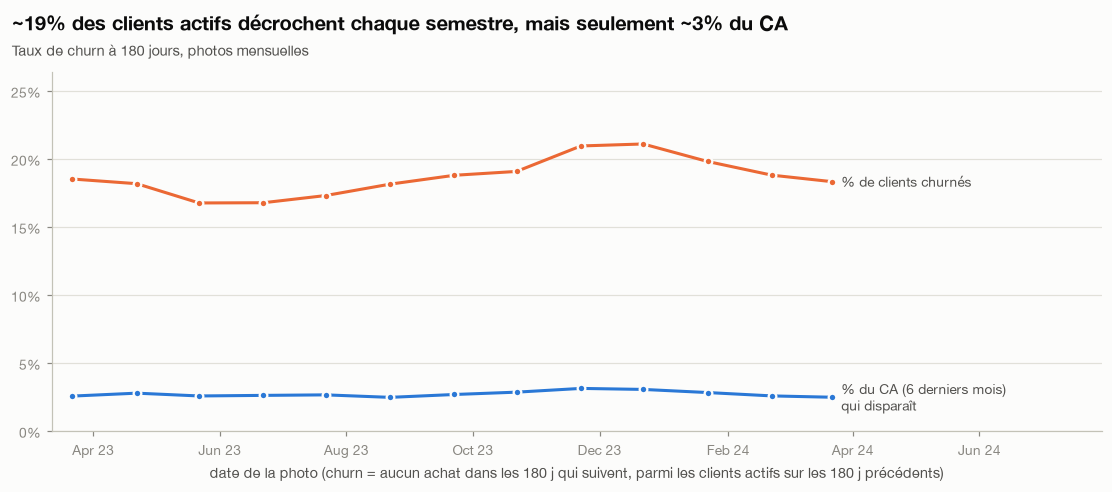

In [21]:
SNAPS_TS = [str(d.date()) for d in pd.date_range("2023-03-22", "2024-03-22", freq=pd.DateOffset(months=1))]
rows = []
for t in SNAPS_TS:
    g_ = light_snap(t)
    g_ = g_[g_["recency"] <= 180]
    c_ = is_churn(g_, 180)
    rows.append(dict(T=pd.Timestamp(t), clients=c_.mean(), ca=(g_["rev180"] * c_).sum() / g_["rev180"].sum()))
ts = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 3.8), constrained_layout=True)
ax.plot(ts["T"], ts["clients"], color=C["orange"], marker="o", ms=5, mec=SURF, mew=1.5)
ax.plot(ts["T"], ts["ca"], color=C["blue"], marker="o", ms=5, mec=SURF, mew=1.5)
label_end(ax, ts["T"].iloc[-1], ts["clients"].iloc[-1], "% de clients churnés")
label_end(ax, ts["T"].iloc[-1], ts["ca"].iloc[-1], "% du CA (6 derniers mois)\nqui disparaît")
pct_axis(ax)
ax.set_ylim(0, ts["clients"].max() * 1.25)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
ax.set_xlim(ts["T"].iloc[0] - pd.Timedelta(days=10), ts["T"].iloc[-1] + pd.Timedelta(days=130))
ax.set_xlabel("date de la photo (churn = aucun achat dans les 180 j qui suivent, parmi les clients actifs sur les 180 j précédents)")
headline(fig, f"~{ts['clients'].mean():.0%} des clients actifs décrochent chaque semestre, mais seulement ~{ts['ca'].mean():.0%} du CA",
         "Taux de churn à 180 jours, photos mensuelles")
plt.show()

Le churn en nombre de clients est **stable dans le temps** (17 % à 21 %, léger pic sur les photos de décembre) ; le **CA concerné est ~7 fois plus faible** (2,5 % à 3,2 %). Un modèle devra donc être évalué **en valeur** et pas seulement en nombre de clients.

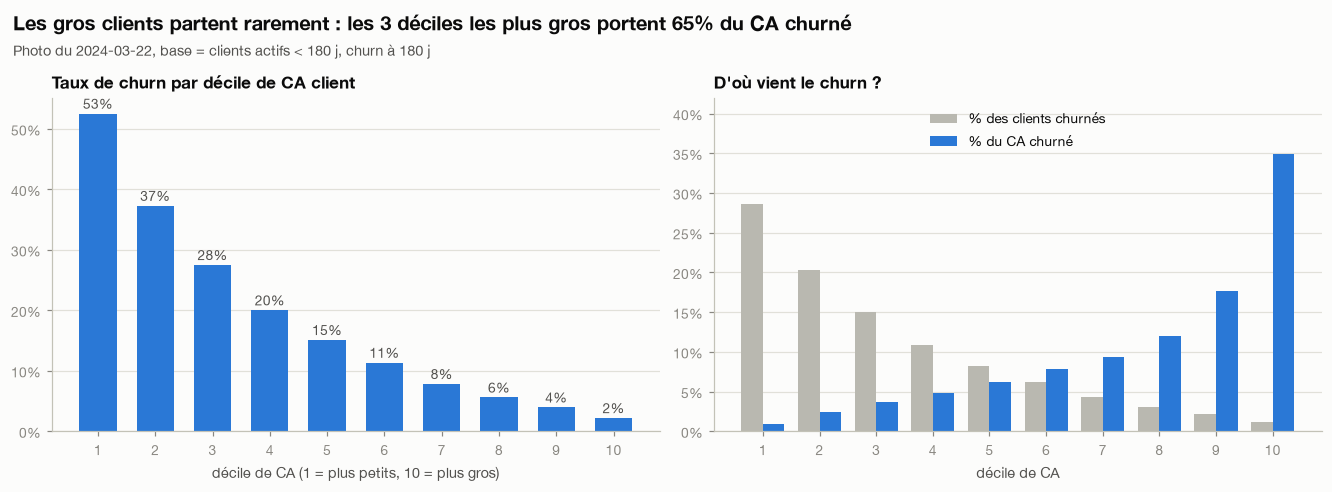

,clients,taux_churn,ca_12m,ca_moyen
rev_decile,,,,
1,"12,012.000",0.525,"2,813,171.637",234.197
2,"12,011.000",0.373,"9,689,045.557",806.681
3,"12,011.000",0.275,"20,195,690.832","1,681.433"
4,"12,012.000",0.200,"36,161,322.224","3,010.433"
5,"12,011.000",0.151,"61,683,237.720","5,135.562"
6,"12,011.000",0.113,"103,974,860.537","8,656.636"
7,"12,012.000",0.078,"178,773,151.712","14,882.880"
8,"12,011.000",0.056,"325,827,155.163","27,127.396"
9,"12,011.000",0.040,"682,426,737.467","56,816.813"


In [22]:
F["rev_decile"] = pd.qcut(F["rev365"].rank(method="first"), 10, labels=range(1, 11)).astype(int)
dec = F.groupby("rev_decile").apply(lambda g_: pd.Series(dict(
    churn=g_["churn"].mean(), rev=g_["rev365"].sum(), rev_churn=(g_["rev365"] * g_["churn"]).sum(), n=len(g_), n_churn=g_["churn"].sum())), include_groups=False)
dec["share_rev_churn"] = dec["rev_churn"] / dec["rev_churn"].sum()
dec["share_n_churn"] = dec["n_churn"] / dec["n_churn"].sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
axes[0].bar(dec.index, dec["churn"], width=0.65, color=C["blue"])
for x, v in dec["churn"].items():
    axes[0].text(x, v + 0.008, f"{v:.0%}", ha="center", fontsize=9, color=INK2)
pct_axis(axes[0])
axes[0].set_title("Taux de churn par décile de CA client")
axes[0].set_xlabel("décile de CA (1 = plus petits, 10 = plus gros)")
axes[0].set_xticks(range(1, 11))
w = 0.38
axes[1].bar(dec.index - w / 2, dec["share_n_churn"], width=w, color=NEUTRAL, label="% des clients churnés")
axes[1].bar(dec.index + w / 2, dec["share_rev_churn"], width=w, color=C["blue"], label="% du CA churné")
pct_axis(axes[1])
axes[1].set_title("D'où vient le churn ?")
axes[1].set_xlabel("décile de CA")
axes[1].set_xticks(range(1, 11))
axes[1].set_ylim(0, 0.42)
axes[1].legend(loc="upper center")
top3 = dec.loc[8:10, "share_rev_churn"].sum()
headline(fig, f"Les gros clients partent rarement : les 3 déciles les plus gros portent {top3:.0%} du CA churné",
         f"Photo du {T_SNAP}, base = clients actifs < {BASE_DAYS} j, churn à {HORIZON} j")
plt.show()
dec[["n", "churn", "rev"]].assign(ca_moyen=lambda d_: d_["rev"] / d_["n"]).rename(columns={"n": "clients", "churn": "taux_churn", "rev": "ca_12m"})

Le churn **en nombre** vient des petits clients (taux élevé), mais le **CA churné** se partage : les petits clients ont un taux de churn élevé pour très peu d'euros, les gros clients un faible taux de churn mais des montants unitaires élevés. Un client du dernier décile pèse en moyenne ~1 000 fois un client du premier (283 k vs 0,2 k de CA annuel) : **la valeur à protéger est dans le haut de la distribution**, là où l'action commerciale (téléphone, visite) est justifiée économiquement et où le client a un interlocuteur dédié.

### Pont de CA : perte pure ou simple volatilité ?
Entre les 180 jours avant et les 180 jours après la photo, d'où vient la variation de CA des clients ? La **perte totale** (client parti) n'est qu'une partie : un client peut aussi **réduire** ses achats sans jamais « partir ». On sépare les deux, en gardant en tête que le CA d'un client fluctue naturellement d'une période à l'autre.

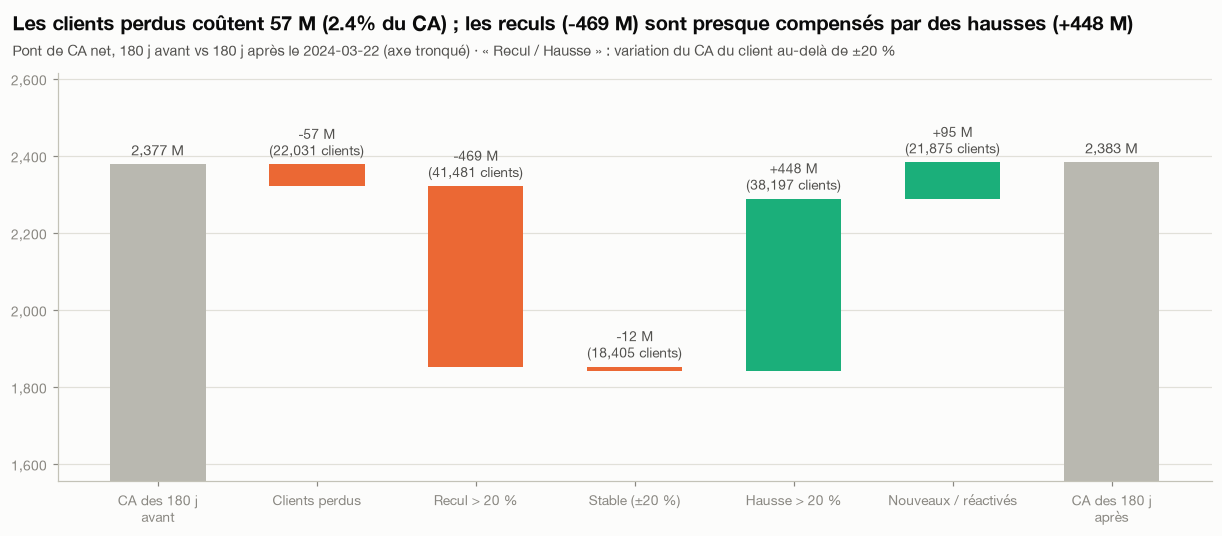

In [23]:
bridge = q(f"""
WITH p AS (
    SELECT client_id,
           coalesce(sum(rev_net) FILTER (WHERE d >= DATE '{T_SNAP}' - 180 AND d < DATE '{T_SNAP}'), 0) AS prev_net,
           coalesce(sum(rev_pos) FILTER (WHERE d >= DATE '{T_SNAP}' - 180 AND d < DATE '{T_SNAP}'), 0) AS prev_pos,
           coalesce(sum(rev_net) FILTER (WHERE d >= DATE '{T_SNAP}' AND d < DATE '{T_SNAP}' + 180), 0) AS next_net,
           coalesce(sum(rev_pos) FILTER (WHERE d >= DATE '{T_SNAP}' AND d < DATE '{T_SNAP}' + 180), 0) AS next_pos
    FROM cd GROUP BY 1)
SELECT * FROM p WHERE prev_pos > 0 OR next_pos > 0""")
bridge["bucket"] = np.select(
    [bridge.prev_pos == 0, bridge.next_pos == 0, bridge.next_net < 0.8 * bridge.prev_net, bridge.next_net > 1.2 * bridge.prev_net],
    ["Nouveaux / réactivés", "Clients perdus", "Recul > 20 %", "Hausse > 20 %"], default="Stable (±20 %)")
bridge["delta"] = bridge["next_net"] - bridge["prev_net"]
wf = bridge.groupby("bucket").agg(delta=("delta", "sum"), n=("client_id", "count"))
steps = ["Clients perdus", "Recul > 20 %", "Stable (±20 %)", "Hausse > 20 %", "Nouveaux / réactivés"]
start, end = bridge["prev_net"].sum(), bridge["next_net"].sum()
cums = start + wf.loc[steps, "delta"].cumsum()

fig, ax = plt.subplots(figsize=(11, 4.2), constrained_layout=True)
ax.bar(0, start, width=0.6, color=NEUTRAL)
ax.text(0, start + start * 0.01, f"{start / 1e6:,.0f} M", ha="center", fontsize=9.5, color=INK2)
cum = start
for i, st in enumerate(steps, start=1):
    dlt = wf.loc[st, "delta"]
    ax.bar(i, dlt, bottom=cum, width=0.6, color=C["orange"] if dlt < 0 else C["aqua"])
    ax.text(i, max(cum, cum + dlt) + start * 0.01, f"{dlt / 1e6:+,.0f} M\n({wf.loc[st, 'n']:,.0f} clients)", ha="center", fontsize=9, color=INK2)
    cum += dlt
ax.bar(len(steps) + 1, end, width=0.6, color=NEUTRAL)
ax.text(len(steps) + 1, end + start * 0.01, f"{end / 1e6:,.0f} M", ha="center", fontsize=9.5, color=INK2)
ax.set_xticks(range(len(steps) + 2), ["CA des 180 j\navant", *steps, "CA des 180 j\naprès"])
ax.yaxis.set_major_formatter(mtick.FuncFormatter(fmt_m))
ax.set_ylim(min(cums.min(), end) - 0.12 * start, start * 1.1)
ax.grid(axis="x", visible=False)
lost, decline, growth = wf.loc["Clients perdus", "delta"], wf.loc["Recul > 20 %", "delta"], wf.loc["Hausse > 20 %", "delta"]
share_lost_6m = abs(lost) / start
headline(fig, f"Les clients perdus coûtent {abs(lost) / 1e6:,.0f} M ({share_lost_6m:.1%} du CA) ; les reculs ({decline / 1e6:,.0f} M) sont presque compensés par des hausses ({growth / 1e6:+,.0f} M)",
         f"Pont de CA net, 180 j avant vs 180 j après le {T_SNAP} (axe tronqué) · « Recul / Hausse » : variation du CA du client au-delà de ±20 %")
plt.show()

Le **CA bouge énormément client par client** (≈ 20 % du CA recule, ≈ 19 % progresse, chaque semestre), mais ces mouvements **se compensent presque exactement** : l'essentiel est de la **volatilité normale** des achats B2B (chantiers qui démarrent ou finissent, effets de commande groupée), pas de l'érosion. Seule la **perte pure** (clients qui disparaissent) n'est pas compensée à l'identique — et elle est en partie remplacée par les **nouveaux/réactivés**.

Un « recul » est-il au moins **durable** ? On le teste : parmi les clients dont le CA a chuté de plus de 50 % entre les semestres A et B, quelle part n'a toujours pas rebondi au semestre C, comparé à des clients stables ?

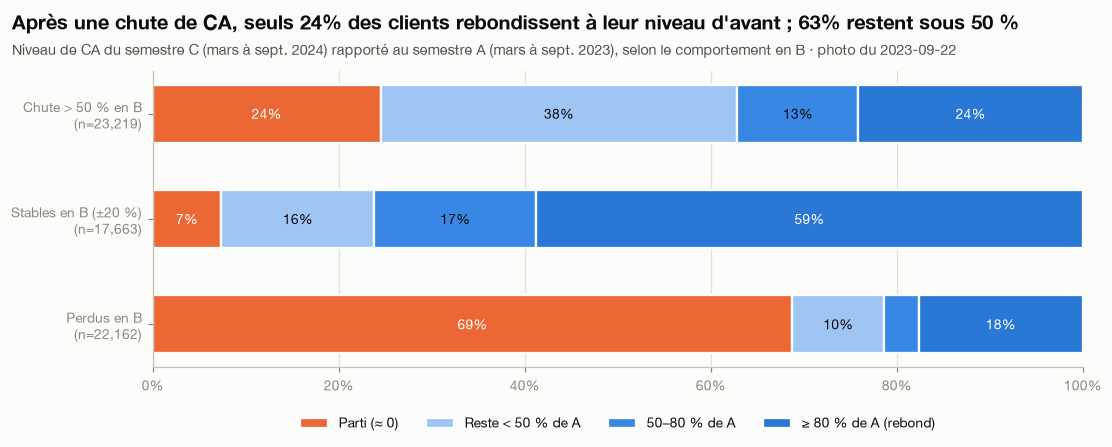

In [24]:
T_P = "2023-09-22"
pers = q(f"""
WITH p AS (
    SELECT client_id,
           coalesce(sum(rev_net) FILTER (WHERE d >= DATE '{T_P}' - 180 AND d < DATE '{T_P}'), 0) AS a,
           coalesce(sum(rev_net) FILTER (WHERE d >= DATE '{T_P}' AND d < DATE '{T_P}' + 180), 0) AS b,
           coalesce(sum(rev_net) FILTER (WHERE d >= DATE '{T_P}' + 180 AND d < DATE '{T_P}' + 360), 0) AS c
    FROM cd GROUP BY 1)
SELECT * FROM p WHERE a > 0""")
grp_drop = pers[(pers["b"] > 0) & (pers["b"] < 0.5 * pers["a"])]
grp_stable = pers[(pers["b"] >= 0.8 * pers["a"]) & (pers["b"] <= 1.2 * pers["a"])]
grp_lost = pers[pers["b"] <= 0]
cats = ["Parti (≈ 0)", "Reste < 50 % de A", "50–80 % de A", "≥ 80 % de A (rebond)"]


def dist(g_):
    r = g_["c"] / g_["a"]
    return pd.Series([(r <= 0.02).mean(), ((r > 0.02) & (r < 0.5)).mean(), ((r >= 0.5) & (r < 0.8)).mean(), (r >= 0.8).mean()], index=cats)


pdist = pd.DataFrame({f"Chute > 50 % en B\n(n={len(grp_drop):,.0f})": dist(grp_drop), f"Stables en B (±20 %)\n(n={len(grp_stable):,.0f})": dist(grp_stable), f"Perdus en B\n(n={len(grp_lost):,.0f})": dist(grp_lost)}).T
fig, ax = plt.subplots(figsize=(10, 3.4), constrained_layout=True)
left = np.zeros(len(pdist))
y = np.arange(len(pdist))[::-1]
for col, colr in zip(cats, [C["orange"], SEQ[1], SEQ[3], C["blue"]]):
    ax.barh(y, pdist[col], left=left, color=colr, height=0.55, label=col, edgecolor=SURF, linewidth=1.5)
    for yi, l, v in zip(y, left, pdist[col]):
        if v > 0.06:
            ax.text(l + v / 2, yi, f"{v:.0%}", ha="center", va="center", fontsize=9, color="white" if colr in (C["orange"], C["blue"]) else INK)
    left += pdist[col].to_numpy()
ax.set_yticks(y, pdist.index)
pct_axis(ax, "x")
ax.set_xlim(0, 1)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
headline(fig, f"Après une chute de CA, seuls {pdist.iloc[0, 3]:.0%} des clients rebondissent à leur niveau d'avant ; {pdist.iloc[0, 0] + pdist.iloc[0, 1]:.0%} restent sous 50 %",
         f"Niveau de CA du semestre C (mars à sept. 2024) rapporté au semestre A (mars à sept. 2023), selon le comportement en B · photo du {T_P}")
plt.show()

Un **recul > 50 % est persistant** pour la majorité des clients concernés : ce n'est donc pas que du bruit, c'est un **signal précoce de départ progressif** (le client réduit son périmètre, partage ses achats avec un concurrent, avant de parfois disparaître). Cela ouvre un 2e label possible — *« chute durable de CA »* — en complément du churn total, et à tester au moment de la modélisation.

### Confrontation aux hypothèses du chiffrage d'équipe
`ClientCo_priorisation_use_cases-2.xlsx` suppose que **5 / 8 / 12 %** du CA part chaque année avec les clients perdus, puis 50 % détectés à temps, 20 % retenus, 24,65 % de marge brute : ≈ **30,6 M de marge** en régime de croisière (central). On mesure ici la 1re hypothèse sur ce dataset, de deux manières :
- **12 mois avant / 12 mois après** le 22/09/2023 : CA des clients sans aucun achat l'année suivante (borne basse : les clients qui reviennent entre-temps ne comptent pas).
- **Semestre, annualisé (×2)** : borne haute (certains « perdus » à 6 mois reviennent avant 12 mois).

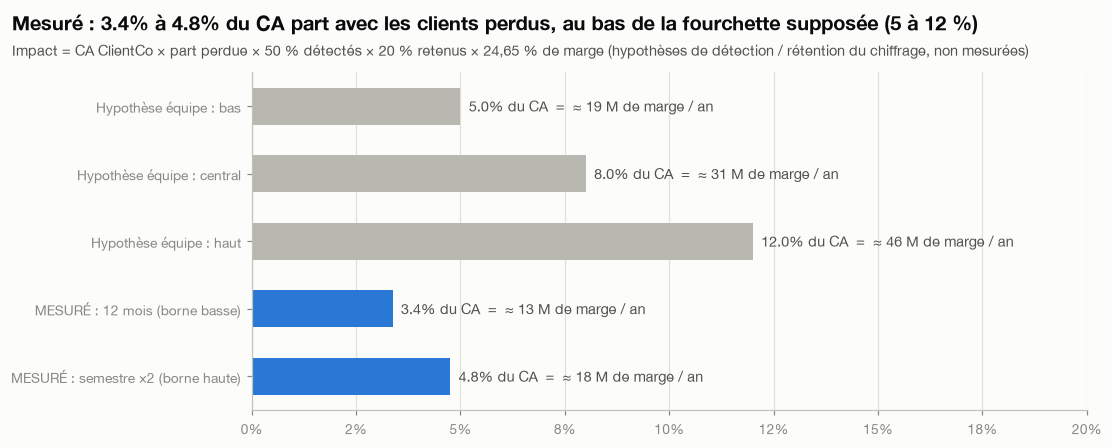

19.9% des clients actifs l'année précédente n'achètent plus du tout l'année suivante, pour 3.4% du CA.


In [25]:
T12 = "2023-09-22"
b12 = q(f"""
WITH p AS (
    SELECT client_id,
           coalesce(sum(rev_net) FILTER (WHERE d >= DATE '{T12}' - 365 AND d < DATE '{T12}'), 0) AS prev_net,
           coalesce(sum(rev_pos) FILTER (WHERE d >= DATE '{T12}' - 365 AND d < DATE '{T12}'), 0) AS prev_pos,
           coalesce(sum(rev_pos) FILTER (WHERE d >= DATE '{T12}' AND d < DATE '{T12}' + 365), 0) AS next_pos
    FROM cd GROUP BY 1)
SELECT * FROM p WHERE prev_pos > 0""")
share_lost = b12.loc[b12["next_pos"] == 0, "prev_net"].sum() / b12["prev_net"].sum()
n_lost12 = (b12["next_pos"] == 0).mean()
share_lost_6m_ann = 2 * share_lost_6m

CA_COMPANY = 15504.0  # M, implicit in the team's xlsx (124.03 M saved = CA x 8 % x 50 % x 20 %)
MARGIN, DETECT, RETAIN = 0.2465, 0.5, 0.2


def impact(share):
    return CA_COMPANY * share * DETECT * RETAIN * MARGIN


scen = pd.DataFrame({"share": [0.05, 0.08, 0.12, share_lost, share_lost_6m_ann]},
                    index=["Hypothèse équipe : bas", "Hypothèse équipe : central", "Hypothèse équipe : haut",
                           "MESURÉ : 12 mois (borne basse)", "MESURÉ : semestre ×2 (borne haute)"])
scen["impact"] = scen["share"].map(impact)

fig, ax = plt.subplots(figsize=(10, 3.4), constrained_layout=True)
y = np.arange(len(scen))[::-1]
ax.barh(y, scen["share"], color=[NEUTRAL] * 3 + [C["blue"]] * 2, height=0.55)
for yi, v, imp in zip(y, scen["share"], scen["impact"]):
    ax.text(v + 0.002, yi, f"{v:.1%} du CA  =  ≈ {imp:,.0f} M de marge / an", va="center", fontsize=9.5, color=INK2)
ax.set_yticks(y, scen.index)
pct_axis(ax, "x")
ax.set_xlim(0, 0.2)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
headline(fig, f"Mesuré : {share_lost:.1%} à {share_lost_6m_ann:.1%} du CA part avec les clients perdus, au bas de la fourchette supposée (5 à 12 %)",
         "Impact = CA ClientCo × part perdue × 50 % détectés × 20 % retenus × 24,65 % de marge (hypothèses de détection / rétention du chiffrage, non mesurées)")
plt.show()
print(f"{n_lost12:.1%} des clients actifs l'année précédente n'achètent plus du tout l'année suivante, pour {share_lost:.1%} du CA.")

**À reporter dans le chiffrage d'équipe** (la ligne « Part du CA perdue chaque année » est marquée « hypothèse à mesurer sur le dataset ») :
- La mesure donne **~3,4 à 4,8 %** : le scénario **bas** (5 %) est le plus réaliste, le central (8 %) paraît **optimiste d'un facteur ~2**. À hypothèses de détection / rétention inchangées, l'impact du churn pur serait de l'ordre de **13 à 18 M de marge / an** au lieu de 30,6 M.
- **Deux réserves** vont dans des sens opposés : (a) un client « perdu » ici peut simplement avoir acheté dans une **agence hors périmètre** du dataset (« subset of stores »), ce qui surestime le churn ; (b) la **chute durable de CA** (clients qui réduisent sans partir) n'est pas dans ce chiffre et peut doubler l'enjeu — c'est un angle à creuser.
- Les taux de détection (50 %) et de rétention (20 %) restent des **hypothèses sans mesure** : un pilote avec groupe témoin est indispensable (« clear success measurement » demandé par la Commercial Director ; « get the Head of Sales onboard » selon OffSupp).